# 02 - Principal component analysis: clines, clusters, and false friends

PCA is the workhorse of population genetics visualization. This notebook

1. builds intuition with two tiny simulations (clusters vs. cline),
2. runs PCA on the real merged dataset, and
3. shows why "PC1 separates population X" is not the same as "X is a natural group".

## What PCA does

Given the genotype matrix $G$ (SNPs x individuals), we center each SNP
(subtract its mean dosage), compute the covariance matrix between individuals,
and find its eigenvectors. The first eigenvector (PC1) is the direction of
maximum variance; PC2 is the next orthogonal direction, and so on. Each
individual gets a **score** on each PC: its projection onto that direction.

PCA is agnostic to labels: it finds directions of maximal (co)variance, not
"the groups". In population genetics those directions usually align with
geography because relatedness decays with distance (isolation by distance),
which produces **clines** rather than separated clusters.

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import balkan_study_io as pio

FIG = ROOT / "results" / "figures"
NB = ROOT / "data" / "processed" / "nb01"
NB02 = ROOT / "data" / "processed" / "nb02"
NB02.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)
print("root:", ROOT)

root: .


## 1. Warm-up: PCA on two 2D clouds

First a case with genuine discrete groups: two Gaussian clouds. Then the same
amount of points arranged along a line (a *cline*). PCA is just a rotation of
the coordinate system, so it does not "know" which situation it is in.

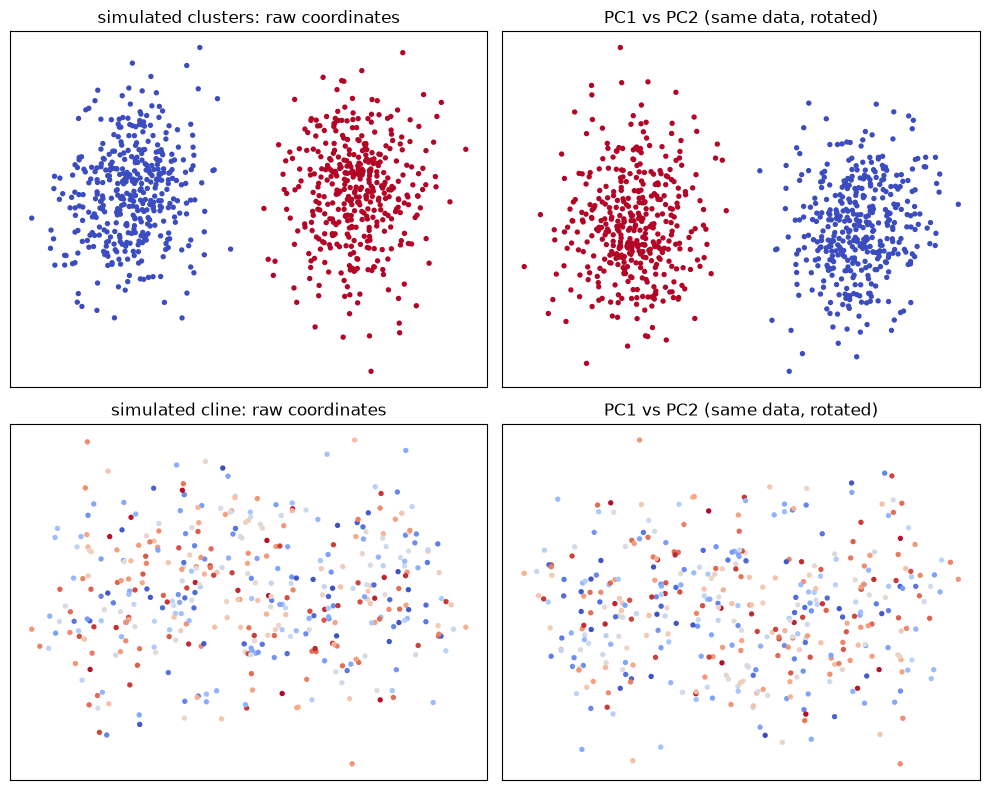

In [2]:
n = 400
cluster_a = rng.normal([-2, 0], 0.6, size=(n, 2))
cluster_b = rng.normal([2, 0], 0.6, size=(n, 2))
clusters = np.vstack([cluster_a, cluster_b])

t = rng.uniform(0, 1, n)
cline = np.stack([np.linspace(-3, 3, n) + rng.normal(0, 0.4, n),
                  rng.normal(0, 0.8, n)], axis=1)

def pca2d(X):
    Xc = X - X.mean(0)
    values, vectors = np.linalg.eigh(Xc.T @ Xc / len(Xc))
    order = np.argsort(values)[::-1]
    return Xc @ vectors[:, order], values[order]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (data, title, color) in enumerate([
        (clusters, "simulated clusters", np.r_[np.zeros(n), np.ones(n)]),
        (cline, "simulated cline", t)]):
    scores, values = pca2d(data)
    axes[row, 0].scatter(data[:, 0], data[:, 1], c=color, cmap="coolwarm", s=8)
    axes[row, 0].set_title(f"{title}: raw coordinates")
    axes[row, 1].scatter(scores[:, 0], scores[:, 1], c=color, cmap="coolwarm", s=8)
    axes[row, 1].set_title("PC1 vs PC2 (same data, rotated)")
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "nb02_sim_2d.png", dpi=130); plt.show()

In both cases PC1 is the long axis. The difference - two blobs vs. a
continuum - is a property of the data, not of PCA. Any clustering method run
on the second panel will still return clusters.

## 2. More realistic: genotypes from clusters vs. an admixed cline

Now simulate 20,000 SNPs for 300 people from a two-way admixture model. Each
SNP has a frequency `p0` in source population 0 and `p1` in source
population 1; an individual with ancestry proportion `a` draws genotypes from
`(1-a)*p0 + a*p1`. In the first dataset `a` is 0 or 1 (two discrete
populations); in the second, `a` is continuously distributed (a cline).

We standardize each SNP (z-score) and run PCA, i.e. what tools like
`smartpca` / `plink2 --pca` do.

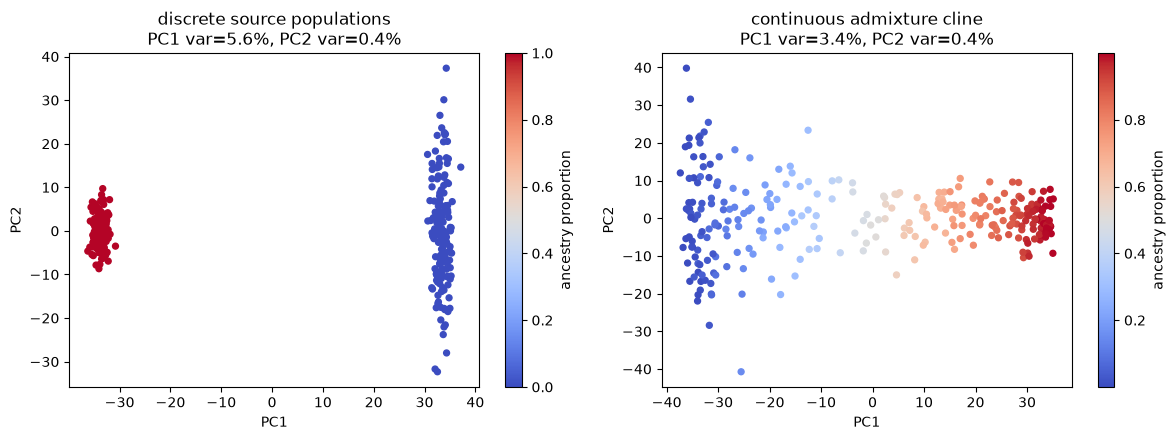

In [3]:
n_ind, n_snp = 300, 20000
p0 = rng.uniform(0.05, 0.95, n_snp)
p1 = np.clip(p0 + rng.normal(0, 0.15, n_snp), 0.01, 0.99)

def simulate(ancestry):
    freqs = (1 - ancestry[:, None]) * p0 + ancestry[:, None] * p1
    return rng.binomial(2, np.clip(freqs, 0, 1)).astype(np.float32)

def pca_geno(G, n_components=4):
    Gc = G - G.mean(0, keepdims=True)
    sd = Gc.std(0, keepdims=True)
    sd[sd == 0] = 1
    Z = Gc / sd
    # individuals x SNPs, economy SVD of the individual covariance
    U, S, _ = np.linalg.svd(Z, full_matrices=False)
    scores = U[:, :n_components] * S[:n_components]
    var = S**2 / (S**2).sum()
    return scores, var[:n_components]

anc_discrete = rng.integers(0, 2, n_ind).astype(float)
anc_cline = rng.beta(0.4, 0.4, n_ind)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, ancestry, title in [(axes[0], anc_discrete, "discrete source populations"),
                            (axes[1], anc_cline, "continuous admixture cline")]:
    G = simulate(ancestry)
    scores, var = pca_geno(G)
    sc = ax.scatter(scores[:, 0], scores[:, 1], c=ancestry, cmap="coolwarm", s=18)
    ax.set_title(f"{title}\nPC1 var={var[0]:.1%}, PC2 var={var[1]:.1%}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    plt.colorbar(sc, ax=ax, label="ancestry proportion")
fig.tight_layout(); fig.savefig(FIG / "nb02_sim_geno.png", dpi=130); plt.show()

Both datasets were generated with the **same** two source populations. Only
the distribution of ancestry differs. Yet the left panel looks like "two
groups" and the right like a "gradient". Human variation within regions is
mostly the right-hand picture; the clustering you see depends on sampling,
not on nature having drawn borders.

## 3. PCA on the real data

Population-genetics PCA is usually run in a wide context and then zoomed in,
because the leading PCs are dominated by the largest differences (continents).
We run `plink2 --pca` on the QC'd, LD-pruned merged dataset.

In [4]:
PLINK2 = "plink2"
def run(cmd):
    print("$", " ".join(str(c) for c in cmd))
    result = subprocess.run([str(c) for c in cmd], cwd=ROOT, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-2000:]); print(result.stderr[-2000:]); result.check_returncode()
    return result.stdout

run([PLINK2, "--bfile", NB / "analysis", "--pca", "20", "approx", "--seed", "42", "--out", NB02 / "pca"])
eigenvec = pd.read_csv(NB02 / "pca.eigenvec", sep=r"\s+").rename(columns={"IID": "iid"})
eigenval = pd.read_csv(NB02 / "pca.eigenval", sep=r"\s+", header=None)[0].to_numpy()
meta = pd.read_csv(ROOT / "data" / "metadata" / "modern_merged_samples.tsv", sep="\t")
df = eigenvec.merge(meta, on="iid", how="left")
balkan = {"Bosniac", "Bosnian_Serb", "Serbian", "Montenegrin", "Macedonian", "Kosovar"}
print("variance explained by PC1..PC5:", np.round(eigenval[:5] / eigenval.sum() * 100, 2), "%")

$ plink2 --bfile ./data/processed/nb01/analysis --pca 20 approx --seed 42 --out ./data/processed/nb02/pca


variance explained by PC1..PC5: [34.85 24.72  8.56  7.18  4.75] %


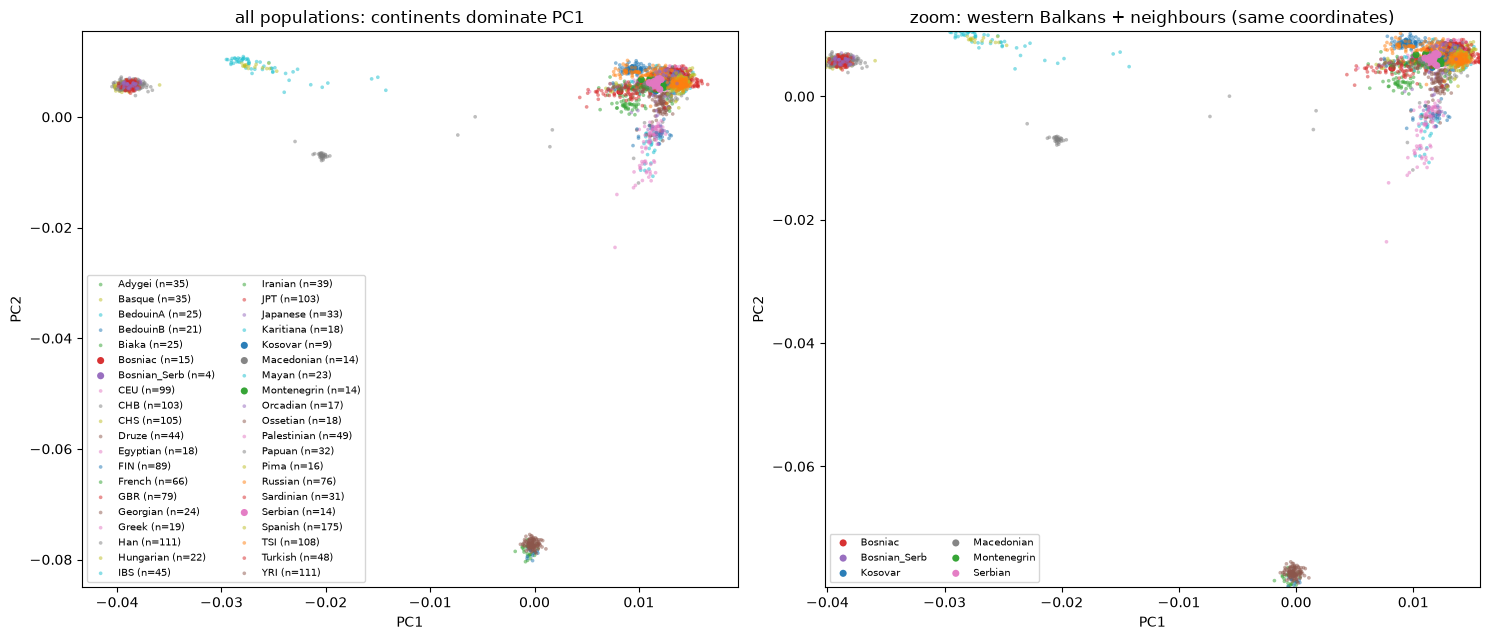

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for g, sub in df.groupby("group"):
    is_b = g in balkan
    axes[0].scatter(sub["PC1"], sub["PC2"], s=26 if is_b else 7, alpha=0.95 if is_b else 0.5,
                    label=f"{g} (n={len(sub)})" if is_b or len(sub) > 15 else None, edgecolors="none")
    axes[1].scatter(sub["PC1"], sub["PC2"], s=26 if is_b else 7, alpha=0.95 if is_b else 0.5,
                    label=g if is_b else None, edgecolors="none")
axes[0].set_title("all populations: continents dominate PC1")
axes[1].set_title("zoom: western Balkans + neighbours (same coordinates)")
axes[1].set_xlim(df["PC1"].quantile(0.002), df["PC1"].quantile(0.998))
axes[1].set_ylim(df["PC2"].quantile(0.002), df["PC2"].quantile(0.998))
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, ncol=2, loc="best")
fig.tight_layout(); fig.savefig(FIG / "nb02_real_pca.png", dpi=130); plt.show()

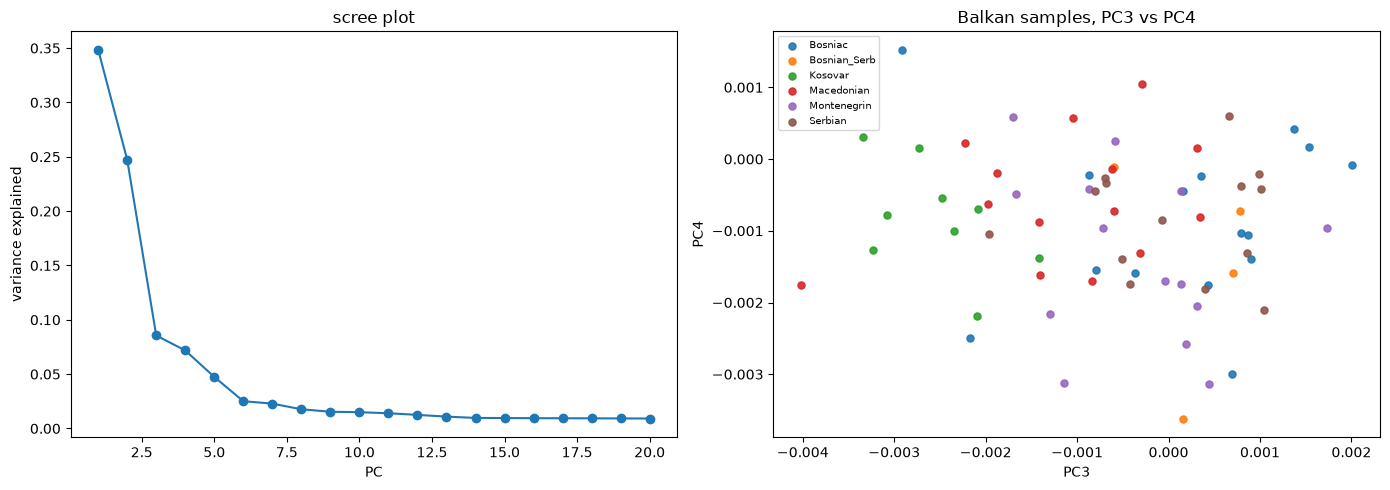

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(eigenval) + 1), eigenval / eigenval.sum(), marker="o")
axes[0].set_xlabel("PC"); axes[0].set_ylabel("variance explained"); axes[0].set_title("scree plot")
for g, sub in df[df["group"].isin(balkan)].groupby("group"):
    axes[1].scatter(sub["PC3"], sub["PC4"], s=26, alpha=0.9, label=g)
axes[1].set_xlabel("PC3"); axes[1].set_ylabel("PC4"); axes[1].set_title("Balkan samples, PC3 vs PC4")
axes[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "nb02_scree_pc34.png", dpi=130); plt.show()

### Reading the real plot

- PC1 mostly separates continents and the Middle East / Caucasus from Europe.
- Within the Balkan zoom the six self-identified nations **overlap heavily**;
  there is a gradient rather than six islands. Kosovars drift toward one edge,
  Croats and Bosniacs toward the other, exactly the north-south cline the
  original paper described.
- This is a *description*, not a test. Notebook 05 quantifies how well
  clusters match nations, and notebook 06 tests prediction directly.

### How many PCs are "real"?

With reference panels, the leading PCs reflect real structure; the scree
slope tells you where the signal decays into noise. `smartpca` uses the
Tracy-Widom test to pick significant axes; `plink2 --pca approx` does not, so
treat PC > ~10 with caution. Always check whether a PC is stable across
random seeds and subsamples.

## Exercises

1. In the genotype simulation, what happens to PC1 if you make the two source
   frequencies more similar (reduce the standard deviation of `p1 - p0`)?
2. Change the cline simulation so ancestry is sampled from a U-shaped
   distribution (most people near 0 or 1). Does PCA now look like clusters?
   This is a taste of how ascertainment changes what structure "looks like".
3. Re-run `plink2 --pca` with a different `--seed` and with `--pca 20`
   (without `approx`). Are the Balkan PCs stable?
4. Project the 70 GEO samples only (no references) with `--pca`: which
   population separates first? Is that a nation?

Next: `03_admixture.ipynb` introduces model-based (soft) clustering.